### [GALT] Vežba 1: GAIA catalogue & basic statistics
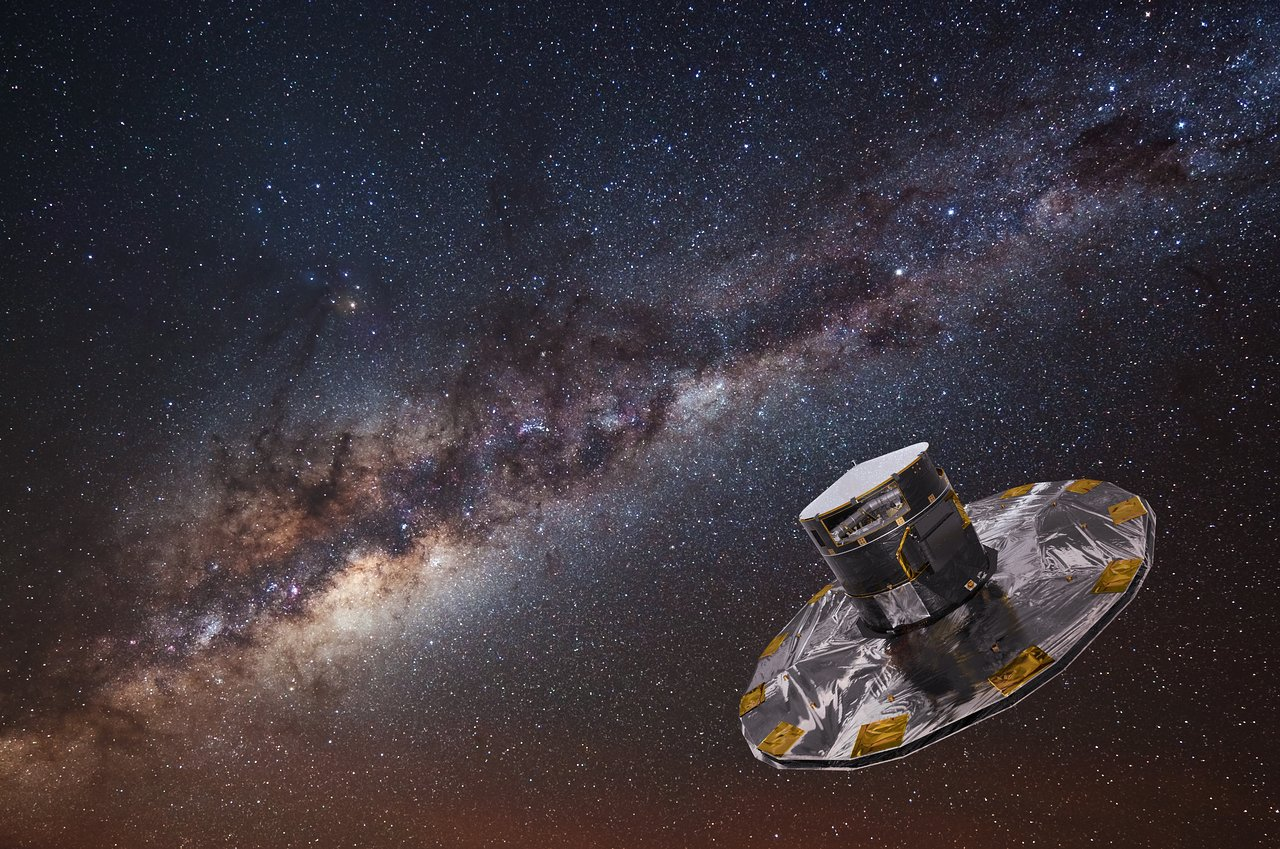

GAIA je svemirska astrometrijska misija Evropske svemirske agencije (ESA), čiji je osnovni cilj precizno merenje položaja i kretanja velikog broja astronomskih objekata. Lansirana je 19. decembra 2013. godine, a naučna posmatranja završena su 15. januara 2025. godine. Njeni podaci nastavljaju da se koriste za proučavanje strukture, kinematike i evolucije Mlečnog puta. Za razliku od teleskopa koji su prvenstveno usmereni na detaljno proučavanje pojedinačnih objekata, GAIA je osmišljena da sistematski posmatra veliki deo neba i stvori izuzetno obiman katalog astronomskih izvora.
Misija je omogućila da se proučavanje Galaksije pomeri sa zaključivanja na osnovu malog broja objekata na statističku analizu miliona i milijardi izvora.
Među najvažnijim rezultatima misije nalaze se:
- precizna merenja položaja zvezda na nebu;
- paralakse, na osnovu kojih možemo procenjivati udaljenosti;
- sopstvena kretanja zvezda po nebeskoj sferi;
- fotometrijska merenja u različitim opsezima talasnih dužina;
- radijalne brzine za deo posmatranih izvora;
- podaci o velikom broju dvojnih zvezda, promenljivih zvezda, jata i drugih astronomskih objekata.

Objavljivanje podataka odvijalo se u nekoliko izdanja. GAIA Data Release 3 (DR3) obuhvata približno 1,8 milijardi izvora, mada količina dostupnih podataka zavisi od vrste merenja i izabranog uzorka.

Podaci koje možemo da nađemo u katalogu su sledeći:

- _source_id_	- jedinstveni identifikator izvora u izdanju kataloga 
- _ra, dec_ - rektascenzija i deklinacija
- _l, b_ -	galaktička dužina i širina
- _parallax_ - paralaksa, u mililučnim sekundama (mas)
- _parallax_error_ - procena greške paralakse
- _pmra, pmdec_ - sopstvena kretanja u pravcu rektascenzije i deklinacije
- _phot_g_mean_mag_ - srednja prividna magnituda u GAIA \(G\) opsegu
- _bp_rp_ - indeks boje, razlika magnituda \(G_{\rm BP}-G_{\rm RP}\)
- _radial_velocity_ - radijalna brzina, dostupna samo za deo izvora

Ako želimo da preuzemo podatke, možemo da odemo na njihovu internet stranicu: https://www.cosmos.esa.int/web/gaia/data-release-3# gde možemo da koristimo _basic_ ili _advanced search_, u zavisnosti od toga šta nam je potrebno. Takođe, možemo direktno iz Python-a da komuniciramo sa bazom podataka, ali je za to neophodno da instaliramo __astroquery__ Python bibiloteku.

### <font color='yellow'>Ideja vežbe: Preuzimanje podataka iz različitih kataloga - za O zvezde iz GAIA DR3 kataloga, a za otvorena i globularna jata sa Vizier-a, i analiza datih podataka.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

Molim vas da ovu ćeliju koristite za sve biblioteke koje ćete naknadno da uvezete:

In [2]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import Angle

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.

Please note the archive will be unavailable on 15 October at 12 CEST for maintenance purposes. Apologies for the inconveniences.


Sada hoćemo da nađemo podatke za zvezde tipa O i sačuvamo u dva odvojena fajla njihove rektascenzije, deklinacije i paralakse.

In [3]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [4]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

Sada preuzimamo podatke za otvorena jata: Optically visible open clusters and Candidates (Dias+ 2002-2015)

https://vizier.cds.unistra.fr/viz-bin/VizieR-3?-source=B/ocl/clusters

In [5]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalogs("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

##### <font color="green">1.  Prikazati grafik DEC od RA, pri čemu razlicitim simbolima oznaciti otvorena zvezdana jata i O zvezde.</font>

In [6]:
# prilagođavam zapis deklinacije i rektascenzije za otvorena jata za lakše crtanje
df_open_clean["DEJ2000"] = df_open_clean["DEJ2000"].apply(lambda x: Angle(x, unit=u.deg).degree)
df_open_clean["RAJ2000"] = df_open_clean["RAJ2000"].apply(lambda x: Angle(x, unit=u.hourangle).degree)

C:\Users\PC\AppData\Local\Temp\ipykernel_8636\365783450.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_open_clean["DEJ2000"] = df_open_clean["DEJ2000"].apply(lambda x: Angle(x, unit=u.deg).degree)
C:\Users\PC\AppData\Local\Temp\ipykernel_8636\365783450.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_open_clean["RAJ2000"] = df_open_clean["RAJ2000"].apply(lambda x: Angle(x, unit=u.hourangle).degree)


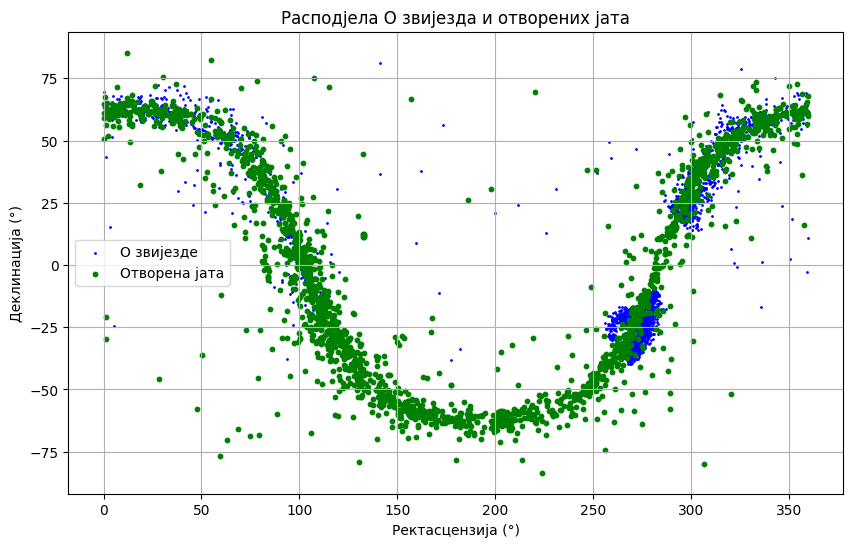

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(df_o["ra"], df_o["dec"], s=1, color='blue', label='O звијезде')
plt.scatter(df_open_clean["RAJ2000"], df_open_clean["DEJ2000"], s=10, color='green', label='Отворена јата')
plt.xlabel("Ректасцензија (°)")
plt.ylabel("Деклинација (°)")
plt.title("Расподјела O звијезда и отворених јата")
plt.legend()
plt.grid()

Овдје су приказани подаци гдје се све налазе у Мљечном путу О звијезде и отворена звјездана јата. Добрим дијелом описују положај галактичка диска/равни на небу у екваторским координатама.

#### <font color="green">2. Odrediti udaljenosti do O zvezda. (Hint: Obratiti pažnju u kojoj jedinici je data paralaksa.)</font>

In [8]:
# paralaksa je u lučnim minutima, prebaciti u parseke
df_o_stars = df_o[["ra", "dec", "parallax"]]
dist = 1000 / (df_o_stars["parallax"]) # rastojanje u parsecima
dist

0       3546.997631
1       1851.148369
2        990.904699
3       2635.261553
4       4088.007820
           ...     
2995    8172.453837
2996    7617.320812
2997    6081.355370
2998    7475.557504
2999    5173.664845
Name: parallax, Length: 3000, dtype: float64

#### <font color="green">3. Određivanje položaja severnog galaktičkog pola</font>

Fitovati podatke funkcijom (zajedno podatke za O zvezde i otvorena jata) koja predstavlja veliki krug na nebeskoj sferi:

$$ \tan(\mathrm{\delta}) = \sin(\mathrm{\alpha}-\mathrm{\alpha}_{\omega})\tan(i), $$

gde su parametri fita $\mathrm{\alpha}_{\omega}$ i $i$.

Položaj severnog galaktičkog pola određuje se pomoću relacija:

$$ \mathrm{\alpha}_{\mathrm{PNG}} = \mathrm{\alpha}_{\omega} - 6\,\mathrm{h},$$

$$ \mathrm{\delta}_{\mathrm{PNG}} = 90^\circ - i.$$

Na osnovu dobijenih parametara fita odrediti koordinate severnog galaktičkog pola.

Dobijene vrednosti uporediti sa usvojenim vrednostima za epohu J2000:

$$ i = 62.87^\circ,
\qquad \mathrm{\alpha}_{\omega} = 18^\mathrm{h}51^\mathrm{m}26^\mathrm{s}.$$

Na grafiku prikazati posmatrane podatke i teorijsku funkciju velikog kruga nebeske sfere, definisanu jednačinom iznad.


Фит α_ω = 284.5874°
Фит i = 61.6160°
Фит α_PNG = 194.5874°
Фит δ_PNG = 28.3840°
J2000 α_PNG = 192.8583°
J2000 δ_PNG = 27.1300°


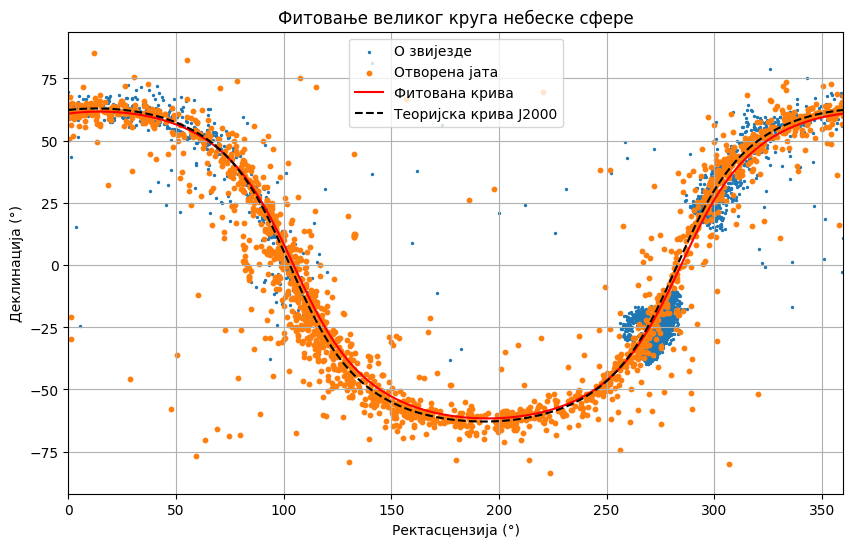

In [9]:
from scipy.optimize import curve_fit
# Učitavam koordinate otvorenih jata
df_open_clean = pd.read_csv("open_clusters_dias.csv")
df_open_clean["DEJ2000"] = Angle(df_open_clean["DEJ2000"], unit=u.deg).degree
df_open_clean["RAJ2000"] = Angle(df_open_clean["RAJ2000"], unit=u.hourangle).degree
# Koordinate O zvezda
df_o_stars = df_o[["ra", "dec"]].copy()
df_o_stars.columns = ["ra", "dec"]
# Spajam podatke u jedan uzorak, bez spajanja po koordinatama
df_open_fit = df_open_clean[["RAJ2000", "DEJ2000"]].copy()
df_open_fit.columns = ["ra", "dec"]
df_merge = pd.concat([df_o_stars, df_open_fit], ignore_index=True).dropna()
# Prebacujem koordinate u radijane
α = np.radians(df_merge["ra"].to_numpy())
δ = np.radians(df_merge["dec"].to_numpy())
# Model velikog kruga; parametri su α_ω i i, oba u radijanima
def fit_funkcija(α, α_ω, i):
    return np.arctan(np.tan(i) * np.sin(α - α_ω))
# Početne vrednosti prema zadatim vrednostima za J2000
α_ω_J2000 = np.radians((18 + 51/60 + 26/3600) * 15)
i_J2000 = np.radians(62.87)
# Fitujem oba parametra
popt, pcov = curve_fit(fit_funkcija, α, δ, p0=[α_ω_J2000, i_J2000], bounds=([α_ω_J2000 - np.pi/2, 0.01],
 [α_ω_J2000 + np.pi/2, np.pi/2 - 0.01]), maxfev=20000)
α_ω_fit, i_fit = popt
# Koordinate sjevernog galaktičkog pola
α_PNG_fit = (α_ω_fit - np.pi/2) % (2*np.pi)
δ_PNG_fit = np.pi/2 - i_fit
print(f"Фит α_ω = {np.degrees(α_ω_fit):.4f}°")
print(f"Фит i = {np.degrees(i_fit):.4f}°")
print(f"Фит α_PNG = {np.degrees(α_PNG_fit):.4f}°")
print(f"Фит δ_PNG = {np.degrees(δ_PNG_fit):.4f}°")
# Teorijske vrednosti za J2000
α_PNG_J2000 = (α_ω_J2000 - np.pi/2) % (2*np.pi)
δ_PNG_J2000 = np.pi/2 - i_J2000
print(f"J2000 α_PNG = {np.degrees(α_PNG_J2000):.4f}°")
print(f"J2000 δ_PNG = {np.degrees(δ_PNG_J2000):.4f}°")
# Crtam podatke i fitovanu krivu
α_plot = np.linspace(0, 2*np.pi, 1000)
plt.figure(figsize=(10, 6))
plt.scatter(df_o_stars["ra"], df_o_stars["dec"], s=2, label="O звијезде")
plt.scatter(df_open_fit["ra"], df_open_fit["dec"], s=10, label="Отворена јата")
plt.plot(np.degrees(α_plot), np.degrees(fit_funkcija(α_plot, *popt)),
         color="red", label="Фитована крива")
plt.plot(np.degrees(α_plot), np.degrees(fit_funkcija(α_plot, α_ω_J2000, i_J2000)),
         color="black", linestyle="--", label="Теоријска крива J2000")
plt.xlabel("Ректасцензија (°)")
plt.ylabel("Деклинација (°)")
plt.title("Фитовање великог круга небеске сфере")
plt.xlim(0, 360)
plt.legend()
plt.grid()
plt.show()


Овдје је видљиво, када се фитује деклинацијски круг на податке, да усвојене вриједности за $α_ω$ и $i$ споменуте у задатку јако добро одговарају фитованом деклинацијском кругу.

#### <font color="green">4. Izračunati galaktičke koordinate l i b za globularna jata. (Možete npr. koristiti funkciju SkyCoord.)</font>

,ID,RAJ2000,DEJ2000,l,b
0,NGC 104,00 24 05.2,-72 04 51,305.895746,-44.889687
1,NGC 288,00 52 47.5,-26 35 24,152.298408,-89.382849
2,NGC 362,01 03 14.3,-70 50 54,301.532861,-46.247850
3,NGC 1261,03 12 15.3,-55 13 01,270.541630,-52.125765
4,Pal 1,03 33 23.0,+79 34 50,130.067030,19.029031
...,...,...,...,...,...
142,NGC 7089,21 33 29.3,-00 49 23,53.377540,-35.777578
143,NGC 7099,21 40 22.0,-23 10 45,27.179945,-46.834884
144,Pal 12,21 46 38.8,-21 15 03,30.512584,-47.680990
145,Pal 13,23 06 44.4,+12 46 19,87.103384,-42.699804


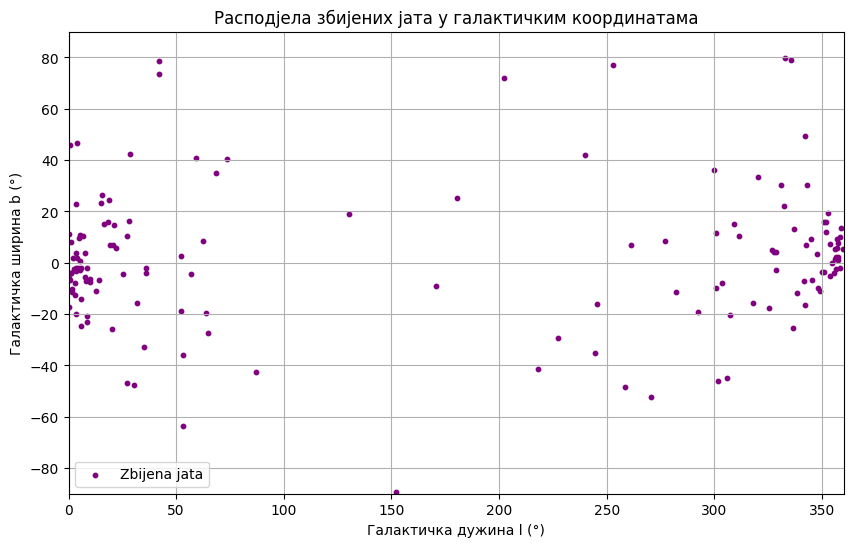

In [10]:
#Pomoću SkyCoord iz astropy.coordinates, pretvaram RA i Dec u galaktičke koordinate (l, b) za O zvijezde i otvorena jata.
from astropy.coordinates import SkyCoord
# Učitavam katalog globularnih jata
df_globular_clean = pd.read_csv("globular_clusters_harris.csv")
# Pretvaram ekvatorijalne koordinate u stepene
ra = Angle(df_globular_clean["RAJ2000"], unit=u.hourangle)
dec = Angle(df_globular_clean["DEJ2000"], unit=u.deg)
# Pretvaram ICRS koordinate u galaktičke koordinate
globular_coords = SkyCoord(ra=ra, dec=dec, frame="icrs")
df_globular_clean["l"] = globular_coords.galactic.l.wrap_at(360*u.deg).degree
df_globular_clean["b"] = globular_coords.galactic.b.degree
# Prikaz rezultata
display(df_globular_clean[["ID", "RAJ2000", "DEJ2000", "l", "b"]])
# Grafički prikaz raspodjele globularnih jata
plt.figure(figsize=(10, 6))
plt.scatter(df_globular_clean["l"], df_globular_clean["b"],
            s=10, color="purple", label="Zbijena jata")
plt.xlabel("Галактичка дужина l (°)")
plt.ylabel("Галактичка ширина b (°)")
plt.title("Расподјела збијених јата у галактичким координатама")
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.legend()
plt.grid()
plt.show()

,RAJ2000,DEJ2000,l,b
0,00 00 12,+60 58 00,116.753380,-1.288937
1,00 00 21,+50 44 30,114.729495,-11.314654
2,00 00 39,+59 14 20,116.468449,-2.994015
3,00 01 37,+64 37 30,117.624517,2.267878
4,00 02 14,+67 25 00,118.220980,4.996072
...,...,...,...,...
2162,23 57 24,+61 38 00,116.559269,-0.567992
2163,23 58 24,+61 12 30,116.588733,-1.008513
2164,23 58 37,+60 02 06,116.375536,-2.162636
2165,23 59 10,+60 41 31,116.575177,-1.533046


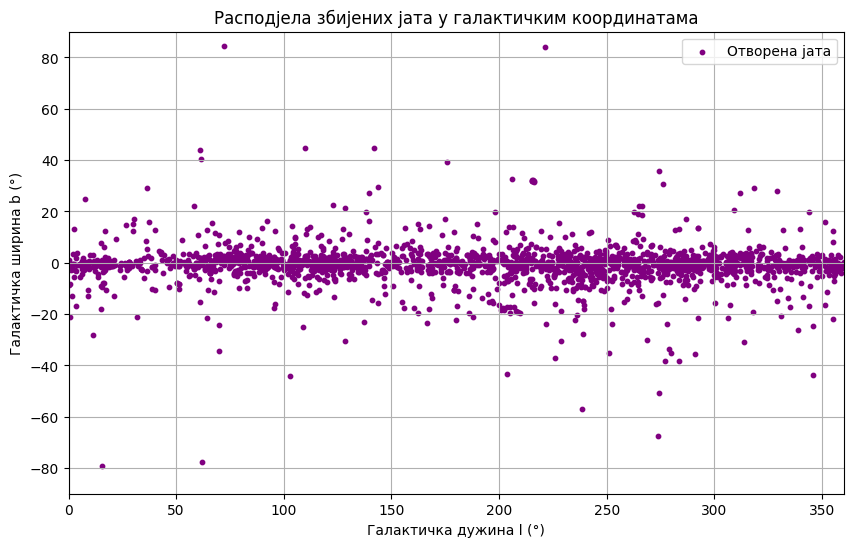

In [11]:
df_open_clean = pd.read_csv("open_clusters_dias.csv")
# Pretvaram ekvatorijalne koordinate u stepene
ra = Angle(df_open_clean["RAJ2000"], unit=u.hourangle)
dec = Angle(df_open_clean["DEJ2000"], unit=u.deg)
# Pretvaram ICRS koordinate u galaktičke koordinate
globular_coords = SkyCoord(ra=ra, dec=dec, frame="icrs")
df_open_clean["l"] = globular_coords.galactic.l.wrap_at(360*u.deg).degree
df_open_clean["b"] = globular_coords.galactic.b.degree
# Prikaz rezultata
display(df_open_clean[["RAJ2000", "DEJ2000", "l", "b"]])
# Grafički prikaz raspodjele globularnih jata
plt.figure(figsize=(10, 6))
plt.scatter(df_open_clean["l"], df_open_clean["b"],
            s=10, color="purple", label="Отворена јата")
plt.xlabel("Галактичка дужина l (°)")
plt.ylabel("Галактичка ширина b (°)")
plt.title("Расподјела збијених јата у галактичким координатама")
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.legend()
plt.grid()
plt.show()

Испоставља се да су збијена јата махом од младих звијезда направљане и да су претежно у галактичком диску - са мало изузетака, што одговара физичким условима, како је у галактичком диску главни материјал за стварање нових звијезда. А како су младе, нису имале времена да се распрше изнад и испод галактичке равни, за разлику од отворених јата.

#### <font color="green">5. Galaktička latituda centra prividne raspodele.</font>
Odrediti galaktičku latitudu centra prividne raspodele globularnih jata. Kreirati prvo zone (pojase) jednakih površina na nebeskoj sferi, njih 10. Površina omotača jednog pojasa je  $2\pi h$, kako je $R=1$ za nebesku sferu. Kako nas zanima da izdelimo nebesku sferu na 10 zona, da je površina jednog omotača zapravo deseti deo površine cele nebeske sfere =>  $2\pi h=0.4\pi$, pa je visina $h = 0.2$, odnosno kako koristimo galaktički koordinatni sistem, prva zona od galaktičkog ekvatora $(b = 0)$ ide do $b = arcsin(0.2)$, kako je $R = 1$, a $sin(b) = h$ (vertikalna visina u odnosu na galaktički ekvator). Za granice zona imamo $b_j = arcsin(0.2(j-6))$, $j = 1, 2, 3, ..., 10$. Na sličan način se mogu naći galaktičke latitude koje odgovaraju centru pojasa, $b_{jc} = arcsin(0.2(j-6) + 0.1)$, $j = 1, 2, 3, ..., 10$. Zapravo, pravi se histogram po b, odnosno broje se objekti u konkretnim zonama. Grafički predstaviti histogram po galaktičkoj latitudi. Galaktička latituda maksimuma raspodele se može naći kao srednja vrednost tako grupisanih posmatranja:
$$b_{max} = \frac{\sum n_ib_i}{\sum n_i},$$
gde je $n_i$ broj zvezda u zoni čija je centralna galaktička latituda $b_i$. Proceniti  $b_{max}$ i za podelu od 20 zona. Koliko očekujemo da je  $b_{max}$, a kolika je računata vrednost?

b_max за 10 зонa = 1.287°


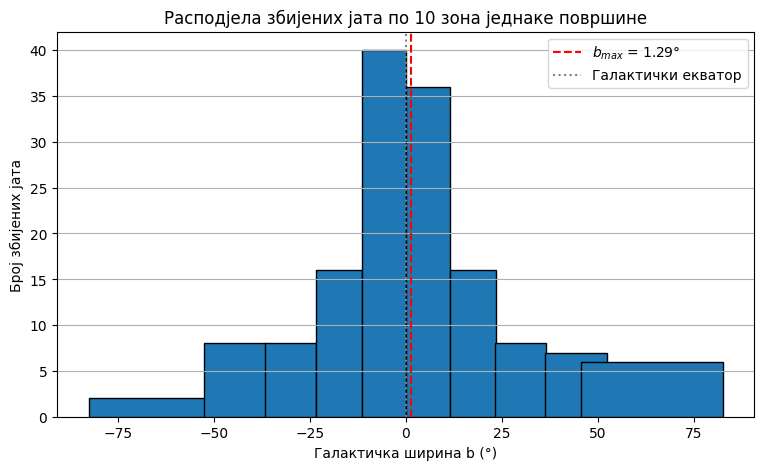

b_max за 20 зона = 1.535°


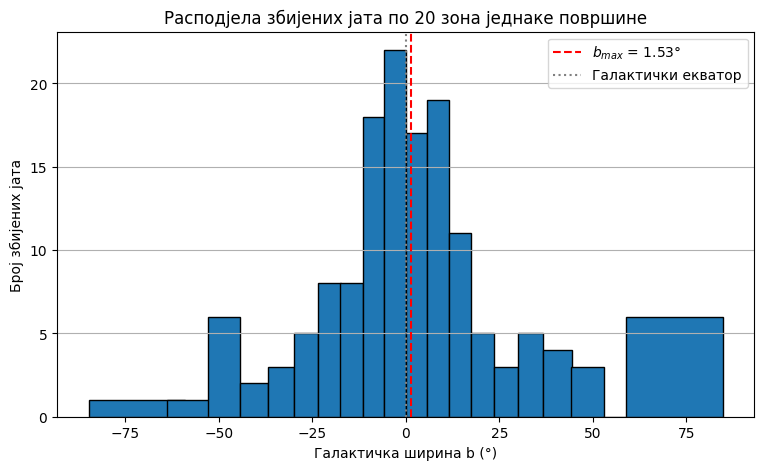

In [13]:
# Галактичка ширина за збијена јата
b = df_globular_clean["b"].dropna().to_numpy()
def b_max(b, N_zona):
    # Granice zona jednake površine: jednaki intervali sin(b)
    sin_b_edges = np.linspace(-1, 1, N_zona + 1)
    b_edges = np.degrees(np.arcsin(sin_b_edges))
    # Centralne galaktičke latitude zona
    sin_b_centers = (sin_b_edges[:-1] + sin_b_edges[1:]) / 2
    b_centers = np.degrees(np.arcsin(sin_b_centers))
    # Broj jata u svakoj zoni
    n_i, _ = np.histogram(b, bins=b_edges)
    # Ponderisana srednja vrednost centralnih latituda
    b_max = np.sum(n_i * b_centers) / np.sum(n_i)
    return b_edges, b_centers, n_i, b_max
# Podela na 10 zona
b_edges_10, b_centers_10, n_10, b_max_10 = b_max(b, 10)
print(f"b_max за 10 зонa = {b_max_10:.3f}°")
plt.figure(figsize=(9, 5))
plt.bar(b_centers_10, n_10, width=np.diff(b_edges_10), align="center", edgecolor="black")
plt.axvline(b_max_10, color="red", linestyle="--", label=f"$b_{{max}}$ = {b_max_10:.2f}°")
plt.axvline(0, color="gray", linestyle=":", label="Галактички екватор")
plt.xlabel("Галактичка ширина b (°)")
plt.ylabel("Број збијених јата")
plt.title("Расподјела збијених јата по 10 зона једнаке површине")
plt.legend()
plt.grid(axis="y")
plt.show()
# Podela na 20 zona
b_edges_20, b_centers_20, n_20, b_max_20 = b_max(b, 20)
print(f"b_max за 20 зона = {b_max_20:.3f}°")
plt.figure(figsize=(9, 5))
plt.bar(b_centers_20, n_20, width=np.diff(b_edges_20), align="center", edgecolor="black")
plt.axvline(b_max_20, color="red", linestyle="--", label=f"$b_{{max}}$ = {b_max_20:.2f}°")
plt.axvline(0, color="gray", linestyle=":", label="Галактички екватор")
plt.xlabel("Галактичка ширина b (°)")
plt.ylabel("Број збијених јата")
plt.title("Расподјела збијених јата по 20 зона једнаке површине")
plt.legend()
plt.grid(axis="y")
plt.show()


#### <font color="green">6. Galaktička longituda centra prividne raspodele, slično kao prethodno.</font>

l_max за 10 зона = 20.904°


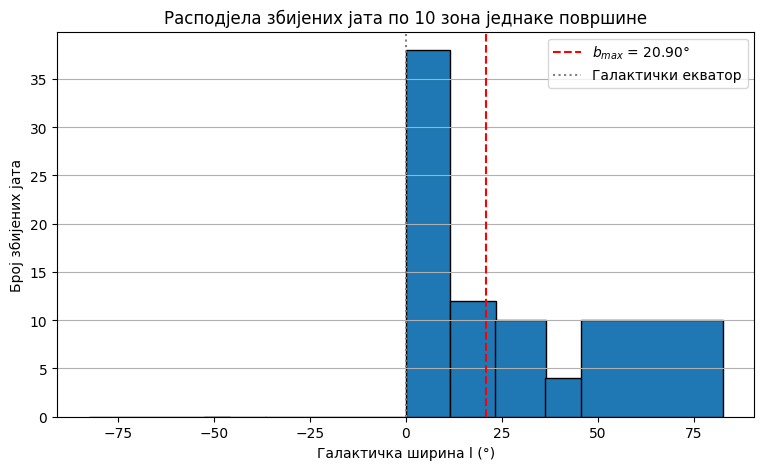

l_max за 20 зона = 20.316°


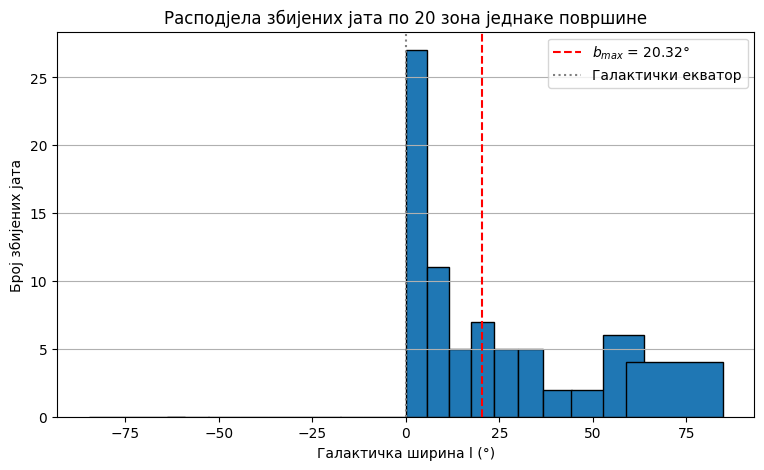

In [14]:
# Галактичка дужина за збијена јата
l = df_globular_clean["l"].dropna().to_numpy()
def l_max(b, N_zona):
    # Granice zona jednake površine: jednaki intervali sin(l)
    sin_l_edges = np.linspace(-1, 1, N_zona + 1)
    l_edges = np.degrees(np.arcsin(sin_l_edges))
    # Centralne galaktičke latitude zona
    sin_l_centers = (sin_l_edges[:-1] + sin_l_edges[1:]) / 2
    l_centers = np.degrees(np.arcsin(sin_l_centers))
    # Broj jata u svakoj zoni
    n_i, _ = np.histogram(l, bins=l_edges)
    # Ponderisana srednja vrijednost centralnih latituda
    l_max = np.sum(n_i * l_centers) / np.sum(n_i)
    return l_edges, l_centers, n_i, l_max
# Podela na 10 zona
l_edges_10, l_centers_10, n_10, l_max_10 = l_max(l, 10)
print(f"l_max за 10 зона = {l_max_10:.3f}°")
plt.figure(figsize=(9, 5))
plt.bar(l_centers_10, n_10, width=np.diff(l_edges_10), align="center", edgecolor="black")
plt.axvline(l_max_10, color="red", linestyle="--", label=f"$b_{{max}}$ = {l_max_10:.2f}°")
plt.axvline(0, color="gray", linestyle=":", label="Галактички екватор")
plt.xlabel("Галактичка ширина l (°)")
plt.ylabel("Број збијених јата")
plt.title("Расподјела збијених јата по 10 зона једнаке површине")
plt.legend()
plt.grid(axis="y")
plt.show()
# Podela na 20 zona
l_edges_20, l_centers_20, n_20, l_max_20 = l_max(l, 20)
print(f"l_max за 20 зона = {l_max_20:.3f}°")
plt.figure(figsize=(9, 5))
plt.bar(l_centers_20, n_20, width=np.diff(l_edges_20), align="center", edgecolor="black")
plt.axvline(l_max_20, color="red", linestyle="--", label=f"$b_{{max}}$ = {l_max_20:.2f}°")
plt.axvline(0, color="gray", linestyle=":", label="Галактички екватор")
plt.xlabel("Галактичка ширина l (°)")
plt.ylabel("Број збијених јата")
plt.title("Расподјела збијених јата по 20 зона једнаке површине")
plt.legend()
plt.grid(axis="y")
plt.show()


Као што се види из претходних вриједности и графика, отворена јата се претежно равномјерно расподјељују у свим правцима наших посматрања, али да се нису расвномјерно расподјељени по ширини диска, већ да су претежно са једне стране.

#### <font color="green">7. Ako pretpostavimo da je centar prividne raspodele globularnih jata upravo centar naše galaksije, kolike su onda l i b galaktičkog centra (koliko očekujemo i koje vrednosti su izračunate)? Kolike su onda RA i DEC za J2000, središta naše galaksije (uporediti sa koordinatama Sag A*).</font>

In [15]:
# Računam galaktičke koordinate centra prividne raspodjele
l_centar = l_max_10
b_centar = b_max_10
# Očekivane galaktičke koordinate centra Galaksije
l_ocekivano = 0.0
b_ocekivano = 0.0
print(f"Очекивано: l = {l_ocekivano:.2f}°, b = {b_ocekivano:.2f}°")
print(f"Израчунато: l = {l_centar:.3f}°, b = {b_centar:.3f}°")
# Pretvaranje galaktičkih koordinata u ekvatorijalne (J2000/ICRS)
centar_galaksije = SkyCoord(l=l_centar * u.deg, b=b_centar * u.deg, frame="galactic")
centar_icrs = centar_galaksije.icrs
print("\nЕкваторијалне координате израчуната система:")
print(f"RA  = {centar_icrs.ra.to_string(unit=u.hourangle, sep=':', precision=2)}")
print(f"DEC = {centar_icrs.dec.to_string(unit=u.deg, sep=':', precision=2, alwayssign=True)}")
# Referentne koordinate Strelca A* (J2000)
sgr_a = SkyCoord("17h45m40.0409s", "-29d00m28.118s", frame="icrs")
print("\nКоориднате Стрелца A* (J2000):")
print(f"RA  = {sgr_a.ra.to_string(unit=u.hourangle, sep=':', precision=2)}")
print(f"DEC = {sgr_a.dec.to_string(unit=u.deg, sep=':', precision=2, alwayssign=True)}")
# Ugaono odstupanje izračunatog centra od Strelca A*
odstupanje = centar_icrs.separation(sgr_a)
print(f"\nУгловно одступање од Стрелца A*: {odstupanje.deg:.3f}°")

Очекивано: l = 0.00°, b = 0.00°
Израчунато: l = 20.904°, b = 1.287°

Екваторијалне координате израчуната система:
RA  = 18:24:36.45
DEC = -10:05:20.29

Коориднате Стрелца A* (J2000):
RA  = 17:45:40.04
DEC = -29:00:28.12

Угловно одступање од Стрелца A*: 21.000°


Испоставља се да, иако прате галактичку раван и диск, да се не може савршено процијенити положај средишта Мљечног пута овим методом привидних расподјела.